In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import os
os.environ['TF_GPU_ALLOCATOR'] = 'cuda_malloc_async'
os.environ['TF_CUDNN_USE_AUTOTUNE'] = '0'

import tensorflow as tf

I0000 00:00:1792060846.118791   89438 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792060847.936347   89438 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792060882.079502   89438 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
path = "/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/pork_datasetv2"
files = os.listdir(path)
train_path = os.path.join(path, "train set")
valid_path = os.path.join(path, "valid set")
test_path = os.path.join(path, "test set")
print("โฟลเดอร์ย่อยในพาธ:", files)

โฟลเดอร์ย่อยในพาธ: ['test set', 'train set', 'unseen data', 'valid set']


In [3]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32

print("จำนวนไฟล์และคลาสใน train set : ")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)
print("\n")

print("จำนวนไฟล์และคลาสใน valid set : ")
valid_dataset = tf.keras.utils.image_dataset_from_directory(
    valid_path,
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)
print("\n")

print("จำนวนไฟล์และคลาสใน test set : ")
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_path,
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)

จำนวนไฟล์และคลาสใน train set : 
Found 2100 files belonging to 2 classes.


I0000 00:00:1792060914.839331   89438 gpu_process_state.cc:208] Using CUDA malloc Async allocator for GPU: 0
I0000 00:00:1792060914.842829   89438 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6




จำนวนไฟล์และคลาสใน valid set : 
Found 300 files belonging to 2 classes.


จำนวนไฟล์และคลาสใน test set : 
Found 600 files belonging to 2 classes.


คลาสทั้งหมดในชุดข้อมูล: ['safe', 'unsafe']


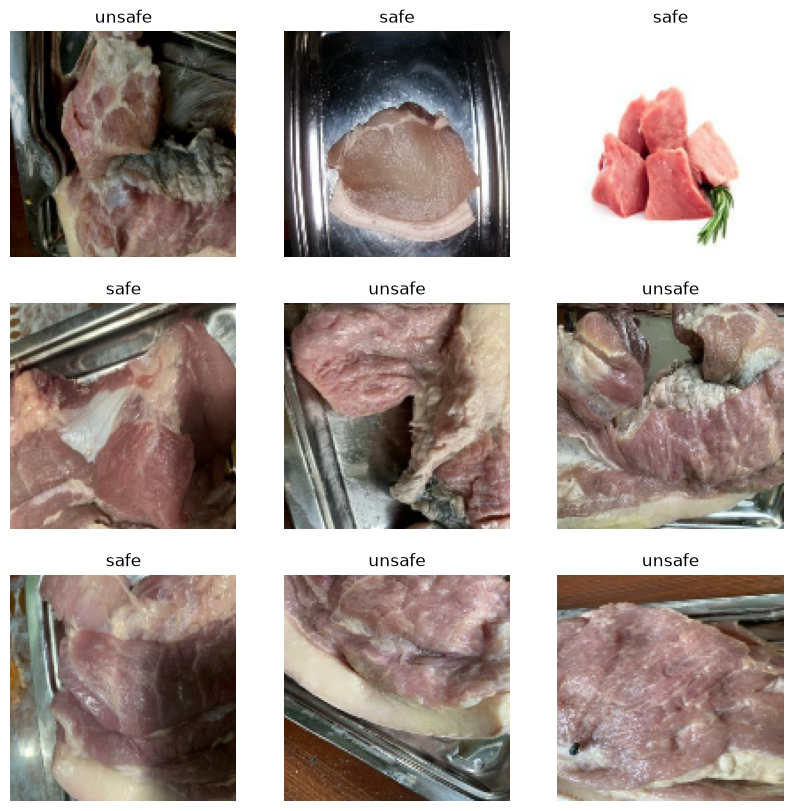

In [4]:
class_names = train_dataset.class_names
print("คลาสทั้งหมดในชุดข้อมูล:", class_names)
plt.figure(figsize=(10, 10)) 
for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

In [5]:
from tensorflow.keras.applications import VGG19
base_model = VGG19(input_shape=(IMAGE_SIZE[0],IMAGE_SIZE[1],3),include_top = False, weights = "imagenet")
base_model.summary()

Model: "vgg19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,024,384 (76.39 MB)

 Trainable params: 20,024,384 (76.39 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
from tensorflow.keras.layers import Rescaling, GlobalAveragePooling2D, Dense, Input, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Normalization

base_model.trainable = False

inputs = Input(shape=(IMAGE_SIZE[0],IMAGE_SIZE[1], 3))
custom_ann = Normalization(mean=[123.675, 116.28, 103.53], variance=[58.395**2, 57.12**2, 57.375**2])(inputs)
custom_ann = base_model(custom_ann)

custom_ann = GlobalAveragePooling2D()(custom_ann)
custom_ann = tf.keras.layers.Dense(32, activation='relu', kernel_initializer='random_normal')(custom_ann)
custom_ann = BatchNormalization()(custom_ann)
custom_ann = tf.keras.layers.Dense(16, activation='relu', kernel_initializer='random_normal')(custom_ann)
custom_ann = BatchNormalization()(custom_ann)
custom_ann = tf.keras.layers.Dense(8, activation='relu', kernel_initializer='random_normal')(custom_ann)
custom_ann = tf.keras.layers.Dense(4, activation='relu', kernel_initializer='random_normal')(custom_ann)
outputs = tf.keras.layers.Dense(units=1, activation='sigmoid')(custom_ann)

model = tf.keras.models.Model(inputs=inputs, outputs=outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 4, 4, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,041,697 (76.45 MB)

 Trainable params: 17,217 (67.25 KB)

 Non-trainable params: 20,024,480 (76.39 MB)

In [7]:
from keras.callbacks import ModelCheckpoint
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss='binary_crossentropy',metrics=['accuracy'])
checkpointer = ModelCheckpoint(filepath='model.weights.best.keras',verbose=0,save_best_only=True)
history = model.fit(train_dataset, validation_data=valid_dataset, epochs=100, callbacks=[checkpointer])

Epoch 1/100


/mnt/c/Users/jiray/ml/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792060941.009256  115659 service.cc:153] XLA service 0x7978f4042270 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792060941.009321  115659 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1792060941.216372  115659 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792060942.018034  115659 cuda_dnn.cc:461] Loaded cuDNN version 92600
I0000 00:00:1792060942.079320  115659 dot_merger.cc:481] Merging Dots in

65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.5413 - loss: 0.6923

I0000 00:00:1792060968.471466  115659 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4028__.80


66/66 ━━━━━━━━━━━━━━━━━━━━ 55s 499ms/step - accuracy: 0.5438 - loss: 0.6923 - val_accuracy: 0.5033 - val_loss: 0.6932
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 125ms/step - accuracy: 0.7319 - loss: 0.6852 - val_accuracy: 0.4900 - val_loss: 0.6929
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 125ms/step - accuracy: 0.8324 - loss: 0.6708 - val_accuracy: 0.5700 - val_loss: 0.6898
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 122ms/step - accuracy: 0.8786 - loss: 0.6479 - val_accuracy: 0.7133 - val_loss: 0.6799
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 123ms/step - accuracy: 0.9148 - loss: 0.6156 - val_accuracy: 0.7567 - val_loss: 0.6588
Epoch 6/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 126ms/step - accuracy: 0.9271 - loss: 0.5717 - val_accuracy: 0.7967 - val_loss: 0.6216
Epoch 7/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 126ms/step - accuracy: 0.9362 - loss: 0.5180 - val_accuracy: 0.8033 - val_loss: 0.5810
Epoch 8/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 9s 138ms/step - accuracy: 0.9471 - loss: 0.4571 - val_accuracy: 0.850

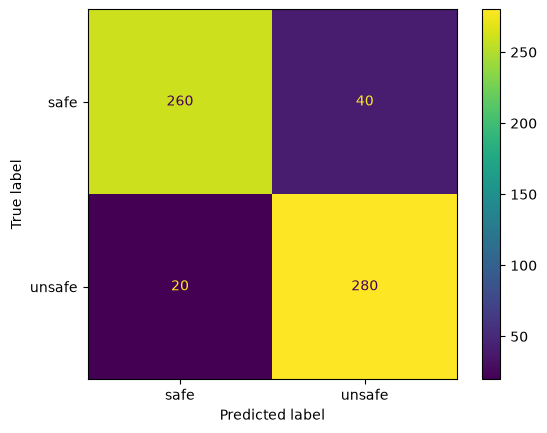

Classification Report:
              precision    recall  f1-score   support

        safe       0.93      0.87      0.90       300
      unsafe       0.88      0.93      0.90       300

    accuracy                           0.90       600
   macro avg       0.90      0.90      0.90       600
weighted avg       0.90      0.90      0.90       600



In [8]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true, y_prob = [], []
for images, labels in test_dataset:
    probs = model.predict(images, verbose=0)
    y_prob.extend(probs.ravel())
    y_true.extend(labels.numpy())
 
y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = (y_prob > 0.5).astype("int32")      # 0 = safe, 1 = unsafe
 
cm = ConfusionMatrixDisplay(
    confusion_matrix(y_true, y_pred),
    display_labels=class_names
)
cm.plot()
plt.show()
 
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

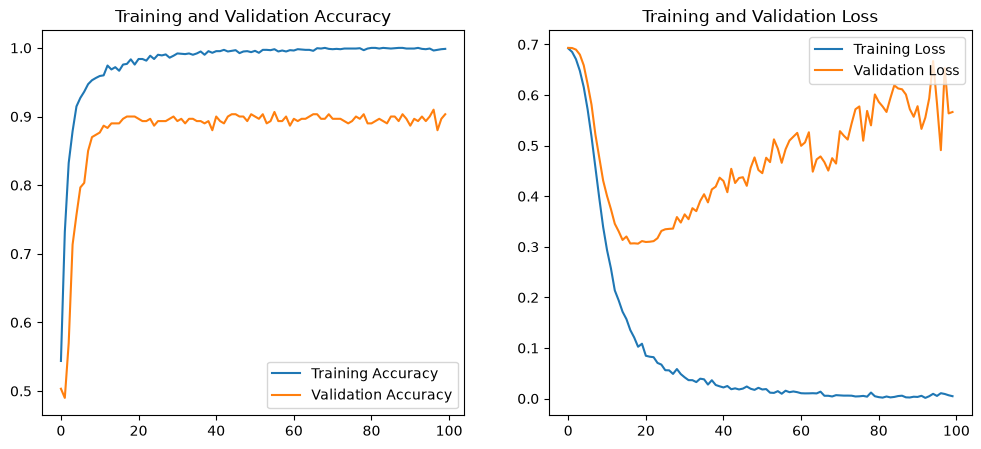

In [9]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# กราฟความแม่นยำ (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# กราฟความสูญเสีย (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

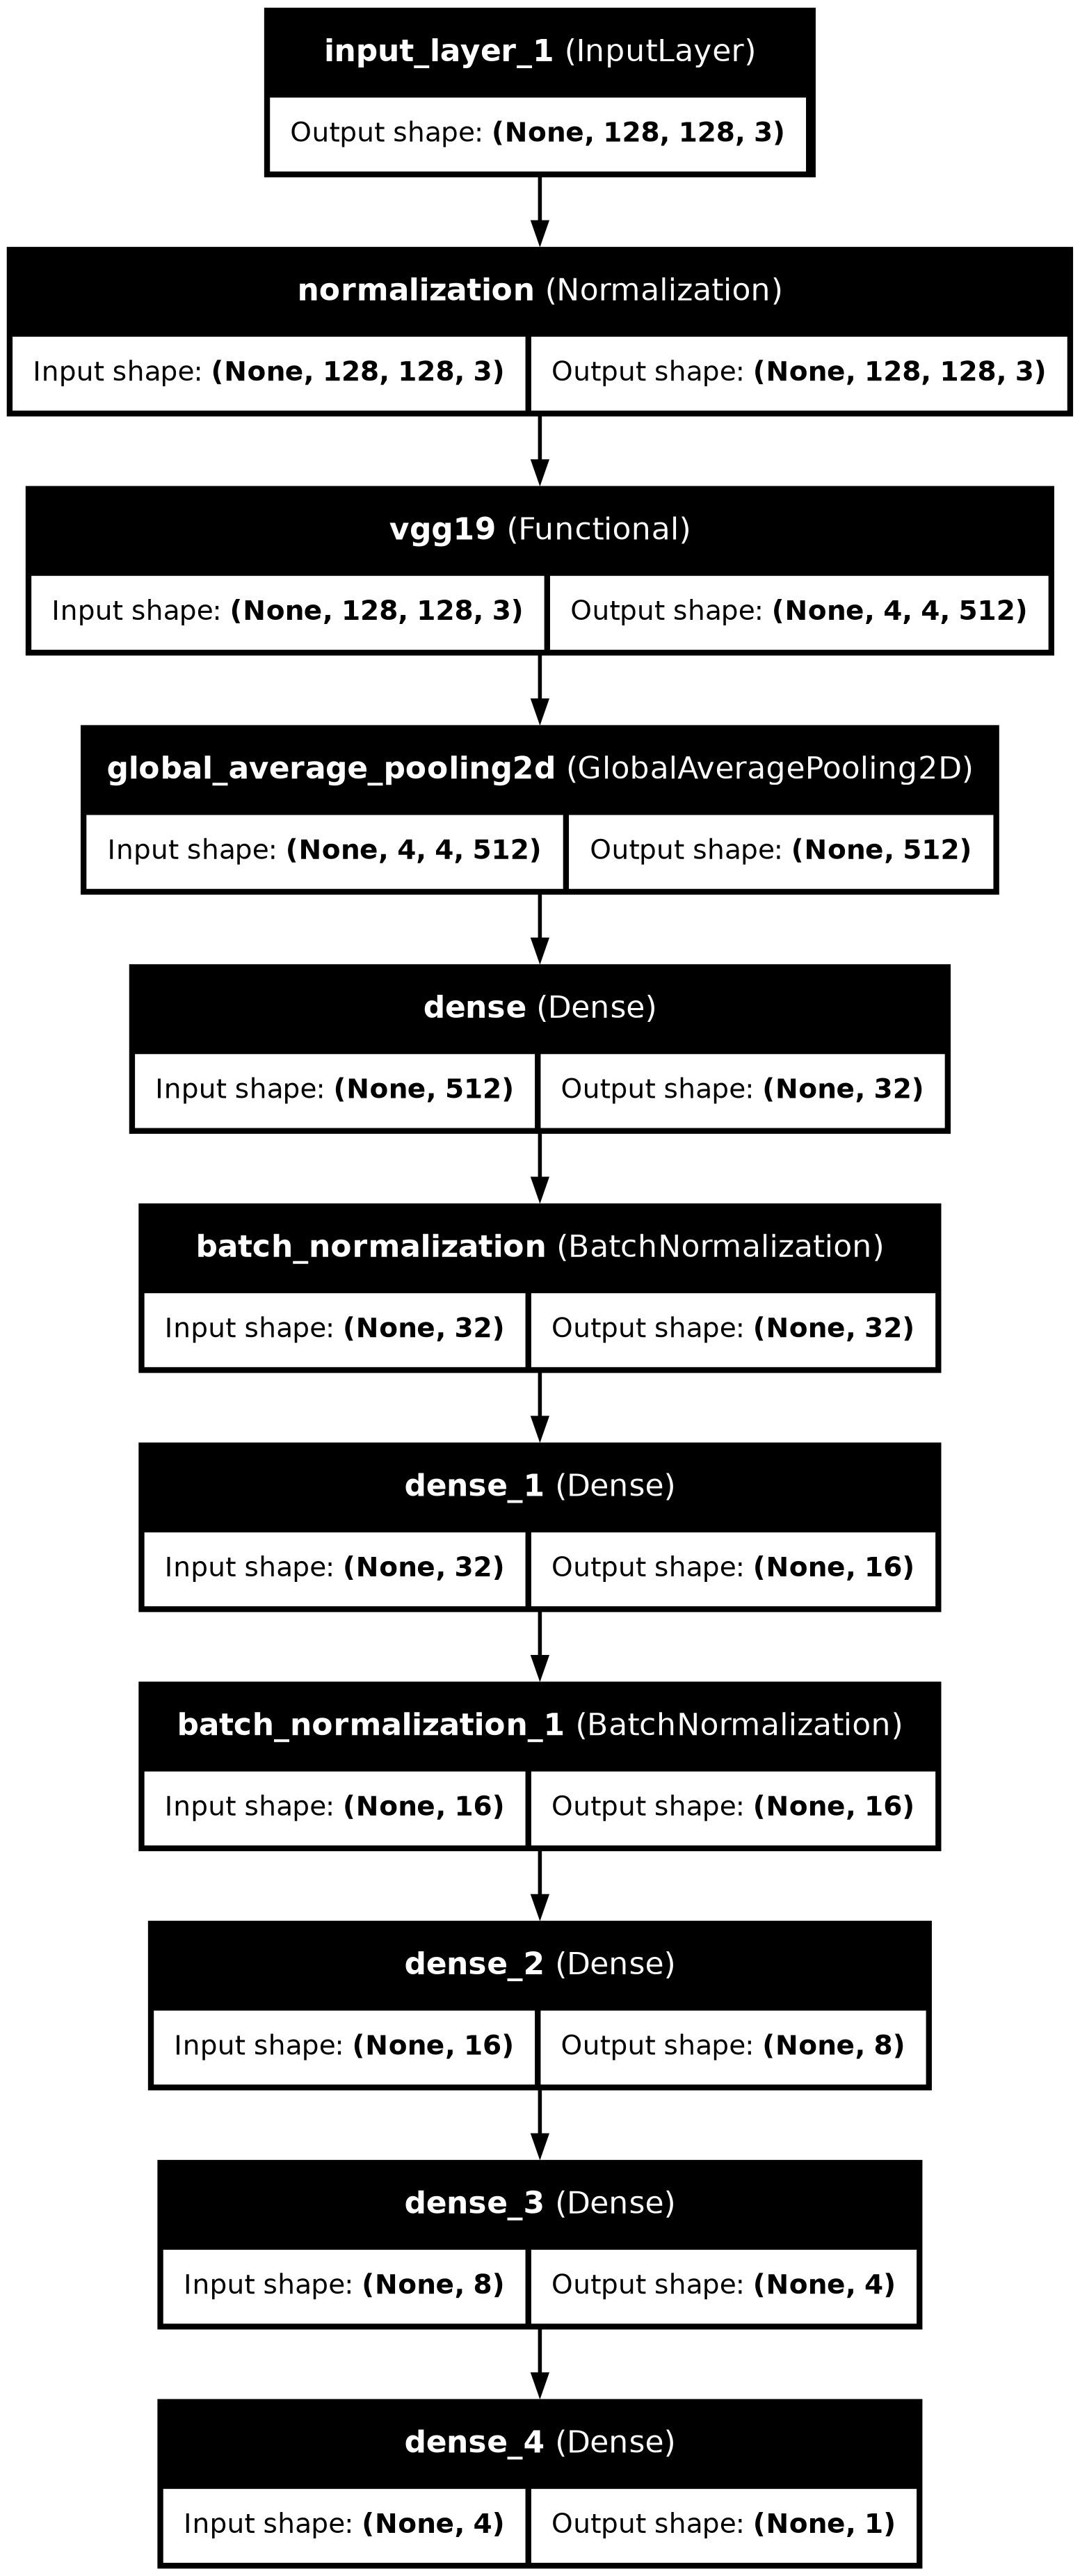

In [10]:
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    show_shapes=True,
    show_layer_names=True
)

In [11]:
model.save('/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/model1_VGG19.h5')
print('saved model to drive')

saved model to drive


In [1]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# 1. กำหนดโฟลเดอร์ที่เก็บภาพใหม่ (เปลี่ยนชื่อโฟลเดอร์ได้ตามต้องการ)
unseen_dir = r"/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/pork_datasetv2/unseen data"

# ดึงเฉพาะไฟล์รูปภาพมาเก็บไว้ในลิสต์
image_filenames = [f for f in os.listdir(unseen_dir) if f.endswith(('.png', '.jpg', '.jpeg'))]

IMAGE_SIZE = (IMAGE_SIZE[0], IMAGE_SIZE[1])
class_names = ['safe', 'unsafe']  # อ้างอิงลำดับตามโฟลเดอร์ Train set

# 2. เตรียมข้อมูล: โหลดภาพและแปลงเป็นอาร์เรย์ (Array)
img_arrays = []
for filename in image_filenames:
    img_path = os.path.join(unseen_dir, filename)
    img = load_img(img_path, target_size=IMAGE_SIZE)
    img_array = img_to_array(img)
    img_arrays.append(img_array)

# นำภาพทั้งหมดมาต่อกันเป็น Batch รูปร่างจะเป็น (จำนวนภาพ, 256, 256, 3)
img_batch = np.array(img_arrays)

# 3. สั่งให้โมเดลทำนายผลรวดเดียวทุกภาพ
print(f"กำลังทำนายภาพทั้งหมด {len(image_filenames)} ภาพ...")
model = tf.keras.models.load_model(
    "/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/model1_VGG19.h5",
    compile=False
)
predictions = model.predict(img_batch)

# 4. พล็อตกราฟแสดงรูปภาพ คลาสที่ทำนายได้ และเปอร์เซ็นต์ความมั่นใจ
plt.figure(figsize=(15, 10))
for i in range(len(image_filenames)):
    # กำหนดให้แสดงผลแถวละ 4 ภาพ
    plt.subplot((len(image_filenames) // 4) + 1, 4, i + 1)
    
    # แสดงรูปภาพ (ต้องแปลงกลับเป็น uint8 เพื่อให้ภาพแสดงสีถูกต้อง)
    plt.imshow(img_arrays[i].astype("uint8"))
    
    # ดึงคะแนน (Score) จาก Sigmoid (0 ถึง 1)
    # ถ้าเกิน 0.5 แปลว่าโมเดลเอนเอียงไปทางคลาส 1 ('unsafe')
    score = predictions[i][0]
    if score > 0.5:
        predicted_class = class_names[1]
        confidence = score * 100
    else:
        predicted_class = class_names[0]
        confidence = (1 - score) * 100
        
    plt.title(f"{predicted_class} ({confidence:.2f}%)")
    plt.axis("off")

plt.tight_layout()
plt.show()

I0000 00:00:1792062251.070612  126817 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792062252.573846  126817 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792062276.268359  126817 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


NameError: name 'os' is not defined

In [11]:
base_model.trainable = True
for layer in base_model.layers[:110]:
    layer.trainable = False
    
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), loss='binary_crossentropy',metrics=['accuracy'])
history = model.fit(train_dataset, validation_data=valid_dataset, epochs=100, callbacks=[checkpointer])

Epoch 1/100


/mnt/c/Users/jiray/ml/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1789815452.346112   77697 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_45284__.80


65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.9870 - loss: 0.0368

I0000 00:00:1789815461.688429   77697 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_45284__.80


66/66 ━━━━━━━━━━━━━━━━━━━━ 17s 199ms/step - accuracy: 0.9867 - loss: 0.0374 - val_accuracy: 0.7967 - val_loss: 0.7403
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 119ms/step - accuracy: 0.9852 - loss: 0.0427 - val_accuracy: 0.8033 - val_loss: 0.7017
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 119ms/step - accuracy: 0.9843 - loss: 0.0493 - val_accuracy: 0.7900 - val_loss: 0.7562
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 118ms/step - accuracy: 0.9886 - loss: 0.0336 - val_accuracy: 0.8000 - val_loss: 0.7332
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 122ms/step - accuracy: 0.9814 - loss: 0.0575 - val_accuracy: 0.7967 - val_loss: 0.8334
Epoch 6/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 118ms/step - accuracy: 0.9905 - loss: 0.0282 - val_accuracy: 0.8167 - val_loss: 0.6707
Epoch 7/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 117ms/step - accuracy: 0.9886 - loss: 0.0333 - val_accuracy: 0.7933 - val_loss: 0.8023
Epoch 8/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 118ms/step - accuracy: 0.9829 - loss: 0.0459 - val_accuracy: 0.796

19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 190ms/step


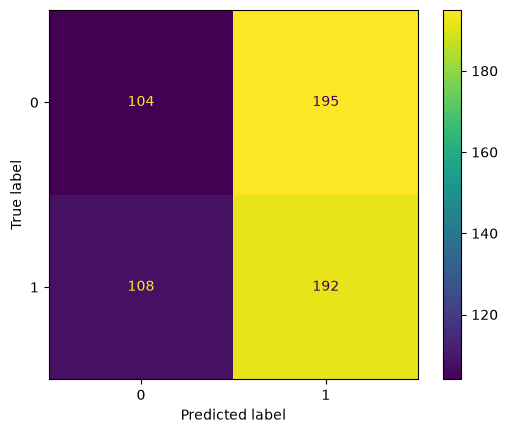

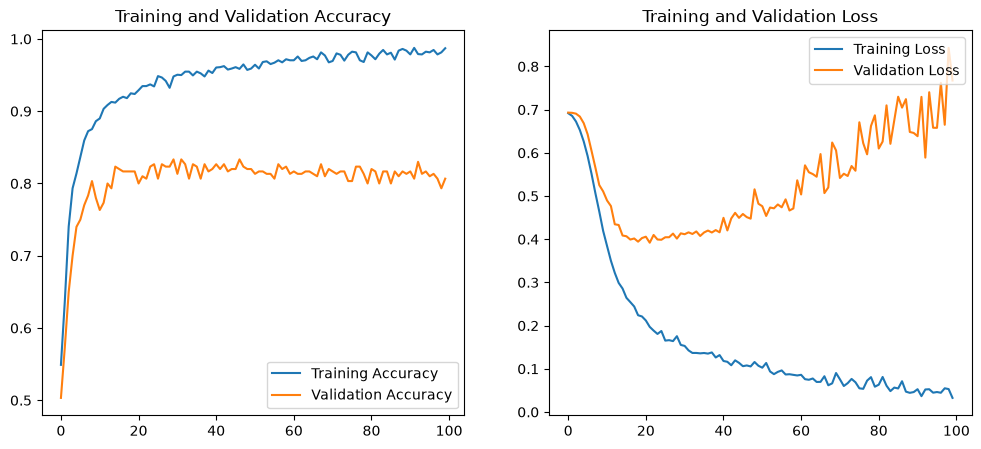

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true, y_prob = [], []
for images, labels in test_dataset:
    probs = model.predict(images, verbose=0)
    y_prob.extend(probs.ravel())
    y_true.extend(labels.numpy())
 
y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = (y_prob > 0.5).astype("int32")      # 0 = safe, 1 = unsafe
 
cm = ConfusionMatrixDisplay(
    confusion_matrix(y_true, y_pred),
    display_labels=class_names
)
cm.plot()
plt.show()
 
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# กราฟความแม่นยำ (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# กราฟความสูญเสีย (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [13]:
model.save('/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/model1_VGG19.h5')
print('saved model to drive')

saved model to drive


กำลังโหลดโมเดล model1_VGG19.h5...


กำลังทำนายภาพทั้งหมด 10 ภาพ...
1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step


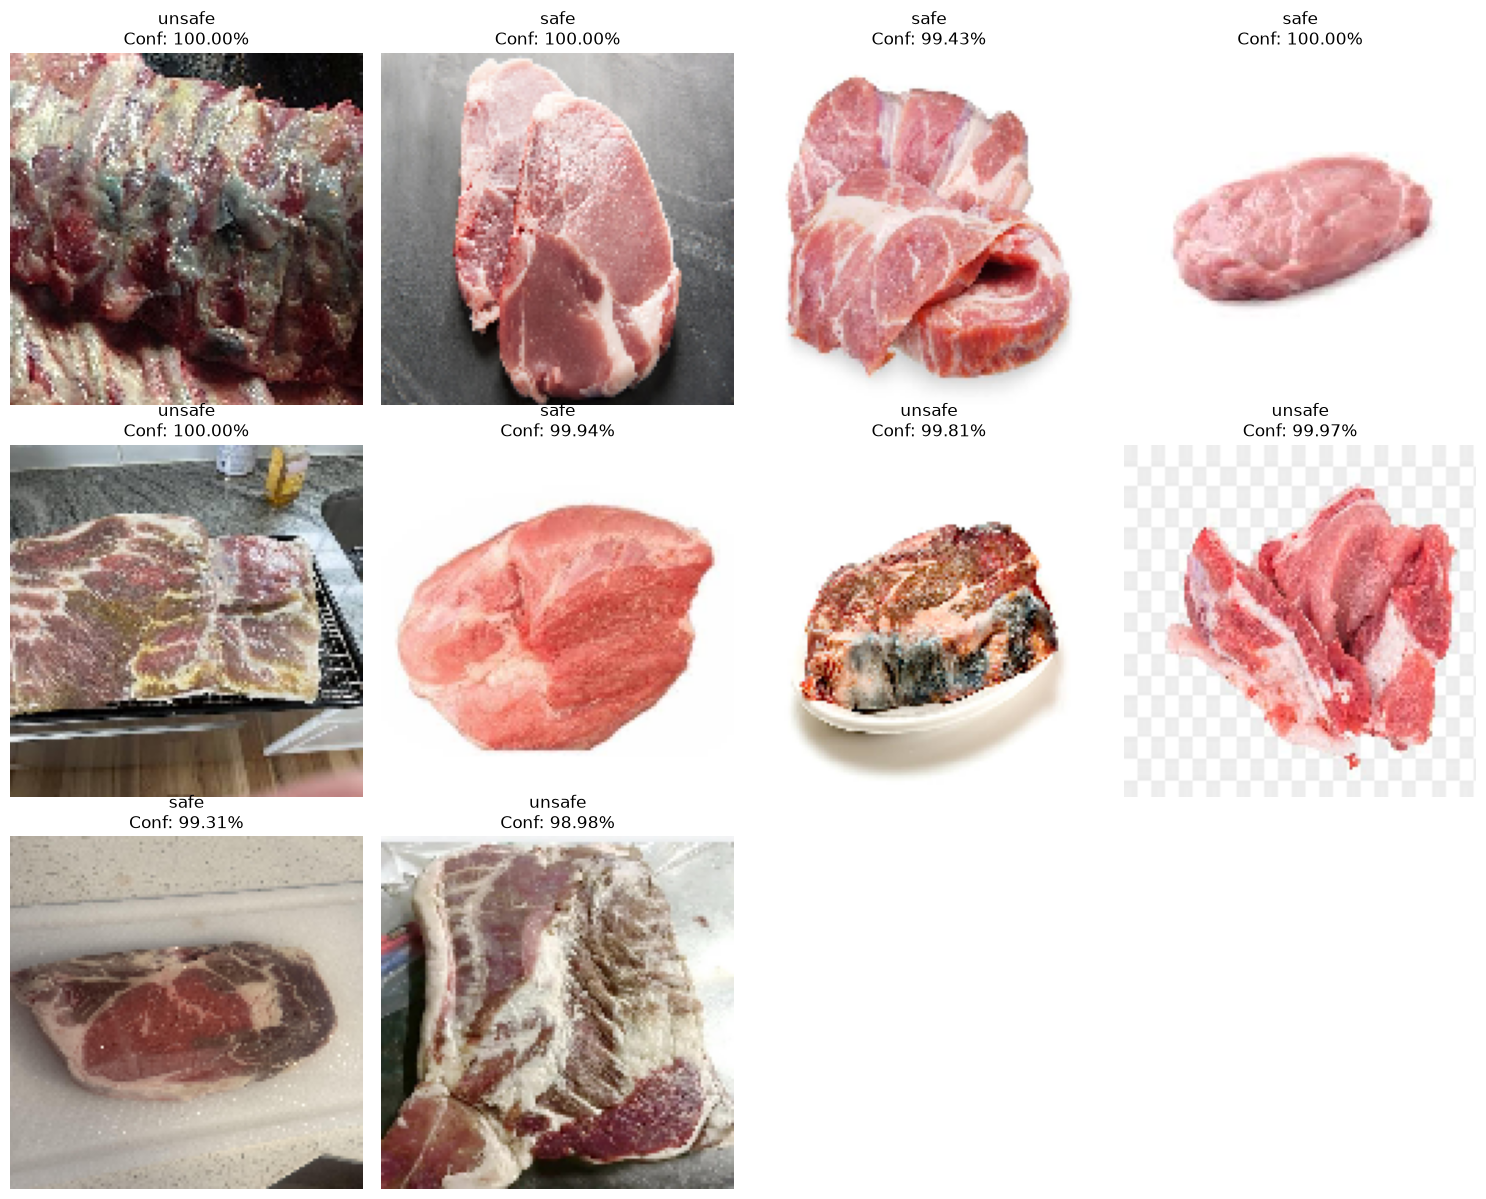

In [ ]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# 1. โหลดโมเดลที่เทรนและเซฟไว้จากไฟล์ .h5
print("กำลังโหลดโมเดล model1_VGG19.h5...")
loaded_model = tf.keras.models.load_model('model1_VGG19.h5')

# 2. กำหนดพาธโฟลเดอร์ unseen data
unseen_dir = r"/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/pork_datasetv2/unseen data"
image_filenames = [f for f in os.listdir(unseen_dir) if f.endswith(('.png', '.jpg', '.jpeg'))]

IMAGE_SIZE = (128, 128)
class_names = ['safe', 'unsafe'] 

# 3. โหลดภาพและจัดเตรียมข้อมูลให้อยู่ในรูป Batch
img_arrays = []
for filename in image_filenames:
    img_path = os.path.join(unseen_dir, filename)
    img = load_img(img_path, target_size=IMAGE_SIZE)
    img_array = img_to_array(img)
    img_arrays.append(img_array)

img_batch = np.array(img_arrays)

# 4. สั่งทำนายผลรวดเดียวทุกภาพด้วยโมเดลที่โหลดมา
print(f"กำลังทำนายภาพทั้งหมด {len(image_filenames)} ภาพ...")
predictions = loaded_model.predict(img_batch)

# 5. พล็อตกราฟแสดงรูปภาพพร้อมผลทำนาย
plt.figure(figsize=(15, 12)) 
for i in range(len(image_filenames)):
    plt.subplot((len(image_filenames) // 4) + 1, 4, i + 1)
    plt.imshow(img_arrays[i].astype("uint8"))
    
    # คำนวณความมั่นใจและคลาส
    score = predictions[i][0]
    if score > 0.5:
        predicted_class = class_names[1]
        confidence = score * 100
    else:
        predicted_class = class_names[0]
        confidence = (1 - score) * 100
        
    # พิมพ์ผลลัพธ์ลงบนหัวรูปภาพ (หลีกเลี่ยงการใช้ภาษาไทยใน Title เพื่อป้องกันฟอนต์สี่เหลี่ยม)
    plt.title(f"{predicted_class}\nConf: {confidence:.2f}%", fontsize=12)
    plt.axis("off")

plt.tight_layout()
plt.show()